In [1]:
import pandas as pd

from PIL import Image

import numpy as np

import torch
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image


import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score




In [2]:
data = pd.read_csv("full_df.csv", encoding= "utf-8")
data.columns = data.columns.str.lower()
data.head(5)


,id,patient age,patient sex,left-fundus,right-fundus,left-diagnostic keywords,right-diagnostic keywords,n,d,g,c,a,h,m,o,filepath,labels,target,filename
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",0_right.jpg
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_right.jpg
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",2_right.jpg
3,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4_right.jpg
4,5,50,Female,5_left.jpg,5_right.jpg,moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",5_right.jpg


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6392 entries, 0 to 6391
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   id                         6392 non-null   int64 
 1   patient age                6392 non-null   int64 
 2   patient sex                6392 non-null   object
 3   left-fundus                6392 non-null   object
 4   right-fundus               6392 non-null   object
 5   left-diagnostic keywords   6392 non-null   object
 6   right-diagnostic keywords  6392 non-null   object
 7   n                          6392 non-null   int64 
 8   d                          6392 non-null   int64 
 9   g                          6392 non-null   int64 
 10  c                          6392 non-null   int64 
 11  a                          6392 non-null   int64 
 12  h                          6392 non-null   int64 
 13  m                          6392 non-null   int64 
 14  o       

In [4]:
for i in data.columns:
    print(f"{i}______________________________________\n{data[i].describe()}")

id______________________________________
count    6392.000000
mean     2271.150814
std      1417.559018
min         0.000000
25%       920.750000
50%      2419.500000
75%      3294.000000
max      4784.000000
Name: id, dtype: float64
patient age______________________________________
count    6392.000000
mean       57.857947
std        11.727737
min         1.000000
25%        51.000000
50%        59.000000
75%        66.000000
max        91.000000
Name: patient age, dtype: float64
patient sex______________________________________
count     6392
unique       2
top       Male
freq      3424
Name: patient sex, dtype: object
left-fundus______________________________________
count           6392
unique          3358
top       0_left.jpg
freq               2
Name: left-fundus, dtype: object
right-fundus______________________________________
count            6392
unique           3358
top       0_right.jpg
freq                2
Name: right-fundus, dtype: object
left-diagnostic keywords_______

In [5]:
#taarget and labels are based on diagnostic of righht eye only of each patient. but actual diagnostic is given using both eye.
data = data.drop(columns=["filename","id", "target","labels","filepath","left-diagnostic keywords","right-diagnostic keywords"])
labels = ['n','d','g','c','a','h','m','o']
data['label_vec'] = data[labels].values.tolist()
data

,patient age,patient sex,left-fundus,right-fundus,n,d,g,c,a,h,m,o,label_vec
0,69,Female,0_left.jpg,0_right.jpg,0,0,0,1,0,0,0,0,"[0, 0, 0, 1, 0, 0, 0, 0]"
1,57,Male,1_left.jpg,1_right.jpg,1,0,0,0,0,0,0,0,"[1, 0, 0, 0, 0, 0, 0, 0]"
2,42,Male,2_left.jpg,2_right.jpg,0,1,0,0,0,0,0,1,"[0, 1, 0, 0, 0, 0, 0, 1]"
3,53,Male,4_left.jpg,4_right.jpg,0,1,0,0,0,0,0,1,"[0, 1, 0, 0, 0, 0, 0, 1]"
4,50,Female,5_left.jpg,5_right.jpg,0,1,0,0,0,0,0,0,"[0, 1, 0, 0, 0, 0, 0, 0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6387,63,Male,4686_left.jpg,4686_right.jpg,0,1,0,0,0,0,0,0,"[0, 1, 0, 0, 0, 0, 0, 0]"
6388,42,Male,4688_left.jpg,4688_right.jpg,0,1,0,0,0,0,0,0,"[0, 1, 0, 0, 0, 0, 0, 0]"
6389,54,Male,4689_left.jpg,4689_right.jpg,0,1,0,0,0,0,0,0,"[0, 1, 0, 0, 0, 0, 0, 0]"
6390,57,Male,4690_left.jpg,4690_right.jpg,0,1,0,0,0,0,0,0,"[0, 1, 0, 0, 0, 0, 0, 0]"


In [6]:
data["left-fundus"] = [f"./all_images/{l_image}" for l_image in data["left-fundus"]]
data["right-fundus"] = [f"./all_images/{r_image}" for r_image in data["right-fundus"]]

In [7]:
print(torch.cuda.is_available())
#print(f"GPU Name: {torch.cuda.get_device_name(0)}") # Optional: check the GPU name


True


In [8]:
#selects which device model will run on. cpu = processor, cuda = GPU.
device = torch.device("cpu")
if torch.cuda.is_available():
    device = torch.device("cuda")
print(device)

cuda


In [9]:
#Normalizing age and encoding gender
data['patient age'] = data['patient age']/100.0
data["patient sex"] = data["patient sex"].map({"Male":1, "Female":0})

In [10]:
#creating a feature vector using patient age and gender
data["attributes_vec"] = data[["patient age","patient sex"]].values.tolist()

In [11]:
data = data[["attributes_vec","left-fundus", "right-fundus","label_vec"]]

In [12]:
data_train, data_test = train_test_split(data, test_size=0.22, random_state=42)
data_train

,attributes_vec,left-fundus,right-fundus,label_vec
5595,"[0.6, 0.0]",C:/Users/krost/Desktop/archive/all_images/3300...,C:/Users/krost/Desktop/archive/all_images/3300...,"[1, 0, 0, 0, 0, 0, 0, 0]"
2799,"[0.59, 0.0]",C:/Users/krost/Desktop/archive/all_images/4231...,C:/Users/krost/Desktop/archive/all_images/4231...,"[0, 1, 0, 0, 0, 0, 0, 0]"
1569,"[0.67, 1.0]",C:/Users/krost/Desktop/archive/all_images/2390...,C:/Users/krost/Desktop/archive/all_images/2390...,"[1, 0, 0, 0, 0, 0, 0, 0]"
3172,"[0.65, 1.0]",C:/Users/krost/Desktop/archive/all_images/4655...,C:/Users/krost/Desktop/archive/all_images/4655...,"[0, 1, 0, 0, 0, 0, 0, 0]"
5487,"[0.53, 0.0]",C:/Users/krost/Desktop/archive/all_images/3182...,C:/Users/krost/Desktop/archive/all_images/3182...,"[1, 0, 0, 0, 0, 0, 0, 0]"
...,...,...,...,...
3772,"[0.71, 0.0]",C:/Users/krost/Desktop/archive/all_images/670_...,C:/Users/krost/Desktop/archive/all_images/670_...,"[0, 0, 0, 0, 0, 0, 0, 1]"
5191,"[0.5, 0.0]",C:/Users/krost/Desktop/archive/all_images/2858...,C:/Users/krost/Desktop/archive/all_images/2858...,"[1, 0, 0, 0, 0, 0, 0, 0]"
5226,"[0.55, 0.0]",C:/Users/krost/Desktop/archive/all_images/2899...,C:/Users/krost/Desktop/archive/all_images/2899...,"[1, 0, 0, 0, 0, 0, 0, 0]"
5390,"[0.66, 0.0]",C:/Users/krost/Desktop/archive/all_images/3079...,C:/Users/krost/Desktop/archive/all_images/3079...,"[1, 0, 0, 0, 0, 0, 0, 0]"


In [13]:
class ModelDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        left_image = Image.open(row["left-fundus"]).convert("RGB")
        right_image = Image.open(row["right-fundus"]).convert("RGB")

        if self.transform:
            left_image = self.transform(left_image)
            right_image = self.transform(right_image)

        attribute = torch.tensor(row["attributes_vec"], dtype=torch.float32)
        target = torch.tensor(row["label_vec"], dtype=torch.float32)

        return left_image, right_image, attribute, target


In [14]:
train_transformed = T.Compose([
    T.Resize((224,224)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.2,0.2,0.2,0.1),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])

val_transformed = T.Compose([
    T.Resize((224,224)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])


In [15]:
class ODIRclassifier(nn.Module):
    def __init__(self, n_classes=8, attr_dim=2):
        super().__init__()

        # Pretrained EfficientNets
        self.left_image_net = models.efficientnet_b0(weights="DEFAULT")
        self.right_image_net = models.efficientnet_b0(weights="DEFAULT")

        f = self.left_image_net.classifier[1].in_features  # 1280

        # Remove the classifier heads
        self.left_image_net.classifier = nn.Identity()
        self.right_image_net.classifier = nn.Identity()

        # Attributes MLP
        self.attributes_vec_fc = nn.Sequential(
            nn.Linear(attr_dim, 16),
            nn.ReLU()
        )

        # Final classifier
        self.classifier = nn.Sequential(
            nn.Linear(f*2 + 16, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, n_classes)
        )

    def forward(self, left_image, right_image, attributes_vec):
        Lf = self.left_image_net(left_image)
        Rf = self.right_image_net(right_image)
        att = self.attributes_vec_fc(attributes_vec)
        combined = torch.cat([Lf, Rf, att], dim=1)
        return self.classifier(combined)


In [16]:
train_ds = ModelDataset(data_train, train_transformed)
val_ds   = ModelDataset(data_test, val_transformed)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=24, shuffle=False)


In [17]:
left_image, right_image, attributes_vec, label_vec = next(iter(train_loader))
print(left_image.shape, right_image.shape, attributes_vec.shape, label_vec.shape)


torch.Size([16, 3, 224, 224]) torch.Size([16, 3, 224, 224]) torch.Size([16, 2]) torch.Size([16, 8])


In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
attr_dim = len(data_train['attributes_vec'].iloc[0])
model = ODIRclassifier(n_classes=8, attr_dim=attr_dim).to(device)
model = ODIRclassifier(n_classes=8, attr_dim=attr_dim).to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4)

for epoch in range(15):
    model.train()
    total_loss = 0

    for left_image, right_image, attributes_vec, label_vec in tqdm(train_loader):
        left_image = left_image.to(device)
        right_image = right_image.to(device)
        attributes_vec = attributes_vec.to(device)
        label_vec = label_vec.to(device)

        optimizer.zero_grad()
        preds = model(left_image, right_image, attributes_vec)
        loss = criterion(preds, label_vec)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} Train Loss: {total_loss/len(train_loader):.4f}")


100%|██████████| 312/312 [01:51<00:00,  2.80it/s]


Epoch 1 Train Loss: 0.3159


100%|██████████| 312/312 [01:47<00:00,  2.91it/s]


Epoch 2 Train Loss: 0.2598


100%|██████████| 312/312 [01:47<00:00,  2.91it/s]


Epoch 3 Train Loss: 0.2256


... (20 outputs left out)

100%|██████████| 312/312 [01:46<00:00,  2.93it/s]


Epoch 14 Train Loss: 0.0427


100%|██████████| 312/312 [01:45<00:00,  2.95it/s]

Epoch 15 Train Loss: 0.0444


In [21]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for left_image,right_image,attributes_vec,label_vec in val_loader:
        left_image,right_image,attributes_vec = left_image.to(device), right_image.to(device), attributes_vec.to(device)
        preds = torch.sigmoid(model(left_image,right_image,attributes_vec))
        y_true.append(label_vec.numpy())
        y_pred.append(preds.cpu().numpy())

y_true = np.vstack(y_true)
y_pred = np.vstack(y_pred)

#This will calculate the ROC-AUC
roc_auc = roc_auc_score(y_true, y_pred, average="macro")

#This will convert probabilities to binary predictions using 0.5 threshold
y_pred_bin = (y_pred >= 0.5).astype(int)

#This will calculate Accuracy and F1-score
accuracy = accuracy_score(y_true, y_pred_bin)
f1 = f1_score(y_true, y_pred_bin, average="macro")

print(f"Mean ROC-AUC: {roc_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1-score: {f1:.4f}")


Mean ROC-AUC: 0.9737
Accuracy: 0.8095
F1-score: 0.8620


In [22]:
#This saves the model
torch.save(model.state_dict(), "odir_model.pth")

In [23]:
#This will calculate the ROC_AUC for each disease
for i, name in enumerate(['N','D','G','C','A','H','M','O']):
    auc = roc_auc_score(y_true[:,i], y_pred[:,i])
    print(name, "AUC:", auc)


N AUC: 0.9722168003618099
D AUC: 0.9655253995179003
G AUC: 0.978642381423085
C AUC: 0.9985739981526793
A AUC: 0.9850634802091112
H AUC: 0.940924528868985
M AUC: 0.9998335414065752
O AUC: 0.9491067896813093


In [ ]:
cam = GradCAM(model=model.left_image_net, target_layers=[model.left_image_net.features[-1]])



In [27]:
def diagnose(probs):
    diseases = ['Normal','Diabetes','Glaucoma','Cataract','AMD','Hypertension','Myopia','Other']
    return [d for i,d in enumerate(diseases) if probs[i] > 0.5]


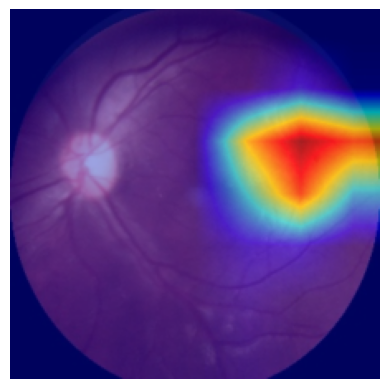

In [29]:
# 1. Select a sample batch from your validation loader
left_img_tensor, right_img_tensor, attr_tensor, target_tensor = next(iter(val_loader))
input_tensor = left_img_tensor[0:1].to(device)  # Shape: [1, 3, 224, 224]

# 2. Run Grad-CAM to generate the normalized activation map (values from 0 to 1)
grayscale_cam = cam(input_tensor=input_tensor, targets=None)
grayscale_cam = grayscale_cam[0, :]  # Extract 2D map for the single image

# 3. Un-normalize the input tensor back to a standard RGB image array [0, 1]
rgb_img = input_tensor[0].cpu().permute(1, 2, 0).numpy()
rgb_img = (rgb_img - rgb_img.min()) / (rgb_img.max() - rgb_img.min())

# 4. Overlay the heat map onto the original RGB eye image
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# 5. Display the result
plt.imshow(visualization)
plt.axis("off")
plt.show()